# Assignment 6: Gaussian Mixture Model and K-Means Clustering

In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt


## Step 1: Initialize GMM Parameters

In [2]:
n = 3000
K = 3

weights1 = [0.34, 0.33, 0.33]
weights2 = [0.34, 0.33, 0.33]

means1 = [
    [-4.0, -2.0],
    [0.5, 3.0],
    [4.5, -1.0]
]

means2 = [
    [-3.5, 3.2],
    [1.0, -3.0],
    [5.5, 3.2]
]

# Spherical, diagonal and full covariance matrices
cov1 = [
    [[1.0, 0.0], [0.0, 1.0]],
    [[1.5, 0.0], [0.0, 0.5]],
    [[1.5, 0.5], [0.5, 1.0]]
]

cov2 = [
    [[1.2, 0.0], [0.0, 1.2]],
    [[0.5, 0.0], [0.0, 2.0]],
    [[2.0, -0.6], [-0.6, 1.0]]
]

print("Samples per class:", n)
print("Components per class:", K)
print("Class 1 weight sum:", sum(weights1))
print("Class 2 weight sum:", sum(weights2))

Samples per class: 3000
Components per class: 3
Class 1 weight sum: 1.0
Class 2 weight sum: 1.0


## Step 2: Generate Gaussian Values Using Box-Muller

In [3]:
def standard_normal():
    u1 = random.random()
    u2 = random.random()

    while u1 == 0:
        u1 = random.random()

    z1 = math.sqrt(-2 * math.log(u1)) * math.cos(2 * math.pi * u2)
    z2 = math.sqrt(-2 * math.log(u1)) * math.sin(2 * math.pi * u2)

    return z1, z2


print("Sample standard normal values:", standard_normal())

Sample standard normal values: (-0.037503956202280475, -1.4567806558371725)


## Step 3: Generate Data Using Covariance Matrices

In [4]:
def generate_gaussian(mean, covariance):
    z1, z2 = standard_normal()

    a = covariance[0][0]
    b = covariance[0][1]
    c = covariance[1][1]

    x = mean[0] + math.sqrt(a) * z1

    y = (
        mean[1]
        + (b / math.sqrt(a)) * z1
        + math.sqrt(c - (b * b / a)) * z2
    )

    return [x, y]


def generate_data(n, weights, means, covariances):
    data = []
    labels = []

    for _ in range(n):
        u = random.random()

        if u < weights[0]:
            component = 0
        elif u < weights[0] + weights[1]:
            component = 1
        else:
            component = 2

        point = generate_gaussian(
            means[component],
            covariances[component]
        )

        data.append(point)
        labels.append(component)

    return np.array(data), np.array(labels)


class1_data, class1_components = generate_data(
    n, weights1, means1, cov1
)

class2_data, class2_components = generate_data(
    n, weights2, means2, cov2
)

print("Class 1 samples:", len(class1_data))
print("Class 2 samples:", len(class2_data))
print("Total samples:", len(class1_data) + len(class2_data))

Class 1 samples: 3000
Class 2 samples: 3000
Total samples: 6000


## Step 4: Plot the Generated Data

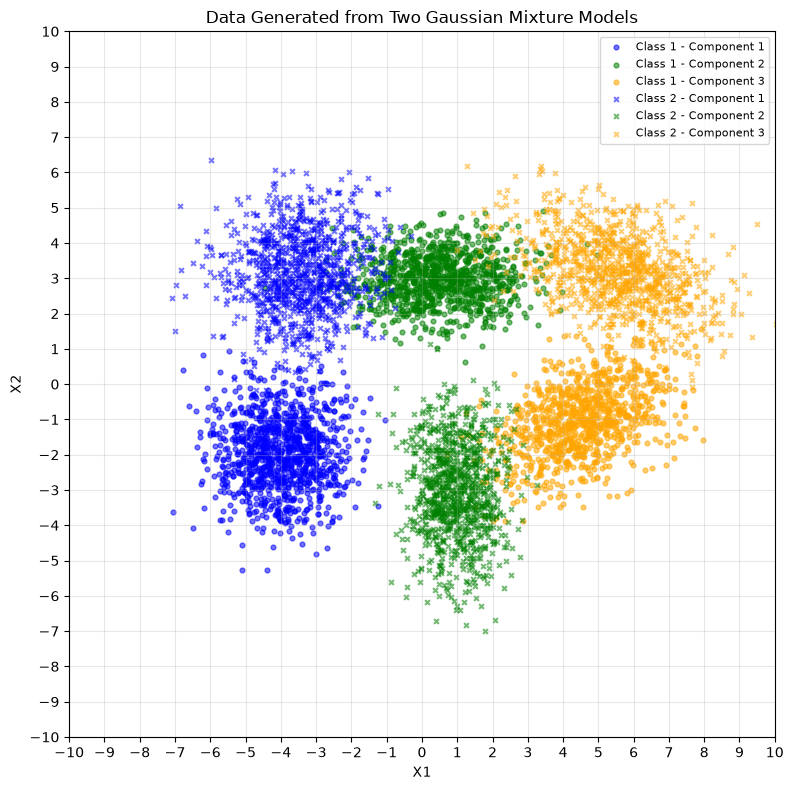

In [5]:
colors = ["blue", "green", "orange"]

def set_axes(ax):
    ax.set_xlim(-10, 10)
    ax.set_ylim(-10, 10)

    ax.set_xticks(range(-10, 11, 1))
    ax.set_yticks(range(-10, 11, 1))

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.grid(True, alpha=0.3)


fig, ax = plt.subplots(figsize=(10, 8))

for k in range(K):
    points = class1_data[class1_components == k]

    ax.scatter(
        points[:, 0], points[:, 1],
        s=12, alpha=0.55,
        color=colors[k], marker="o",
        label=f"Class 1 - Component {k + 1}"
    )

for k in range(K):
    points = class2_data[class2_components == k]

    ax.scatter(
        points[:, 0], points[:, 1],
        s=12, alpha=0.55,
        color=colors[k], marker="x",
        label=f"Class 2 - Component {k + 1}"
    )

ax.set_title("Data Generated from Two Gaussian Mixture Models")
set_axes(ax)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Step 5: Split Data into Training and Testing Sets

In [6]:
def split_data(data, ratio=0.8):
    indices = list(range(len(data)))
    random.shuffle(indices)

    split = int(len(data) * ratio)

    train = data[indices[:split]]
    test = data[indices[split:]]

    return train, test


class1_train, class1_test = split_data(class1_data)
class2_train, class2_test = split_data(class2_data)

print("Class 1 training:", len(class1_train))
print("Class 1 testing:", len(class1_test))
print("Class 2 training:", len(class2_train))
print("Class 2 testing:", len(class2_test))

Class 1 training: 2400
Class 1 testing: 600
Class 2 training: 2400
Class 2 testing: 600


## Step 6: Implement K-Means Clustering

In [7]:
def distance_squared(p1, p2):
    return (
        (p1[0] - p2[0]) ** 2
        + (p1[1] - p2[1]) ** 2
    )


def assign_clusters(data, centroids):
    labels = []

    for point in data:
        distances = [
            distance_squared(point, center)
            for center in centroids
        ]

        labels.append(distances.index(min(distances)))

    return np.array(labels)


def kmeans(data, k, max_iterations=100):
    indices = random.sample(range(len(data)), k)
    centroids = data[indices].copy()

    for _ in range(max_iterations):
        labels = assign_clusters(data, centroids)
        new_centroids = centroids.copy()

        for cluster in range(k):
            points = data[labels == cluster]

            if len(points) > 0:
                new_centroids[cluster] = np.mean(points, axis=0)
            else:
                new_centroids[cluster] = data[
                    random.randrange(len(data))
                ]

        change = sum(
            distance_squared(centroids[i], new_centroids[i])
            for i in range(k)
        )

        centroids = new_centroids

        if change < 0.00001:
            break

    labels = assign_clusters(data, centroids)

    return centroids, labels

## Step 7: Train K-Means on the Training Data

In [8]:
centers1, labels1 = kmeans(class1_train, K)
centers2, labels2 = kmeans(class2_train, K)

print("Class 1 centroids:")
print(np.round(centers1, 3))

print("\nClass 2 centroids:")
print(np.round(centers2, 3))

Class 1 centroids:
[[ 0.485  2.985]
 [-4.003 -1.953]
 [ 4.566 -0.982]]

Class 2 centroids:
[[-3.447  3.129]
 [ 0.965 -3.044]
 [ 5.504  3.211]]


## Step 8: Plot K-Means Clusters and Boundaries

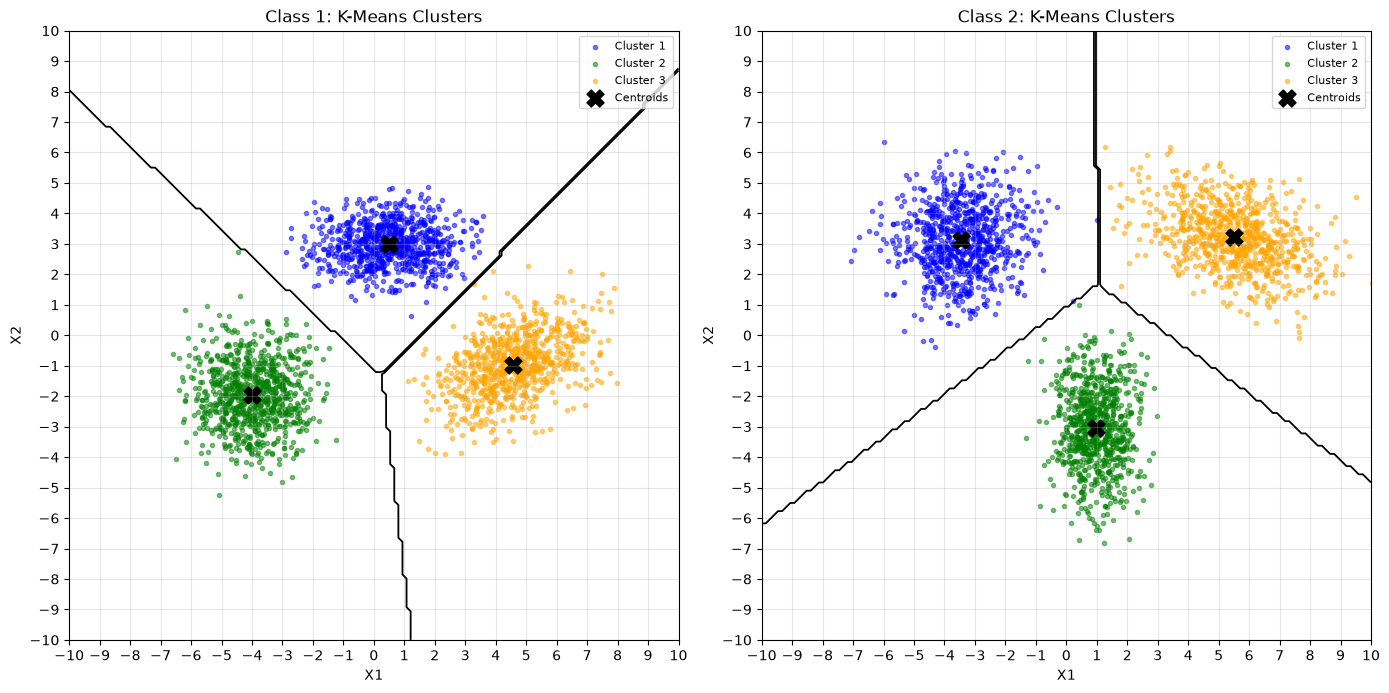

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

training_data = [class1_train, class2_train]
training_labels = [labels1, labels2]
all_centers = [centers1, centers2]

for c, ax in enumerate(axes):
    data = training_data[c]
    labels = training_labels[c]
    centroids = all_centers[c]

    xx, yy = np.meshgrid(
        np.linspace(-10, 10, 150),
        np.linspace(-10, 10, 150)
    )

    grid = np.column_stack((xx.ravel(), yy.ravel()))
    grid_labels = assign_clusters(grid, centroids).reshape(xx.shape)

    ax.contour(
        xx, yy, grid_labels,
        levels=[0.5, 1.5],
        colors="black",
        linewidths=1.3
    )

    for k in range(K):
        points = data[labels == k]

        ax.scatter(
            points[:, 0], points[:, 1],
            s=9, alpha=0.5,
            color=colors[k],
            label=f"Cluster {k + 1}"
        )

    ax.scatter(
        centroids[:, 0], centroids[:, 1],
        marker="X", color="black",
        s=150, label="Centroids"
    )

    ax.set_title(f"Class {c + 1}: K-Means Clusters")
    set_axes(ax)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## Step 9: Classify the Testing Data Using Distortion

In [10]:
def predict_class(point, centers1, centers2):
    distortion1 = min(
        distance_squared(point, center)
        for center in centers1
    )

    distortion2 = min(
        distance_squared(point, center)
        for center in centers2
    )

    if distortion1 <= distortion2:
        return 0
    else:
        return 1


predictions = []
actual_labels = []

for point in class1_test:
    predictions.append(predict_class(point, centers1, centers2))
    actual_labels.append(0)

for point in class2_test:
    predictions.append(predict_class(point, centers1, centers2))
    actual_labels.append(1)

predictions = np.array(predictions)
actual_labels = np.array(actual_labels)


## Step 10: Evaluate Classification Performance

In [11]:
confusion = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(actual_labels, predictions):
    confusion[actual, predicted] += 1

accuracy = np.trace(confusion) / np.sum(confusion) * 100

print("Confusion Matrix")
print(confusion)

print(f"\nClassification accuracy: {accuracy:.2f}%")

for c in range(2):
    TP = confusion[c, c]
    FP = np.sum(confusion[:, c]) - TP
    FN = np.sum(confusion[c, :]) - TP

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(
        f"Class {c + 1}: "
        f"Precision={precision:.3f}, "
        f"Recall={recall:.3f}, "
        f"F1-score={f1:.3f}"
    )

Confusion Matrix
[[564  36]
 [ 23 577]]

Classification accuracy: 95.08%
Class 1: Precision=0.961, Recall=0.940, F1-score=0.950
Class 2: Precision=0.941, Recall=0.962, F1-score=0.951


## Step 11: Plot the Classification Decision Boundary

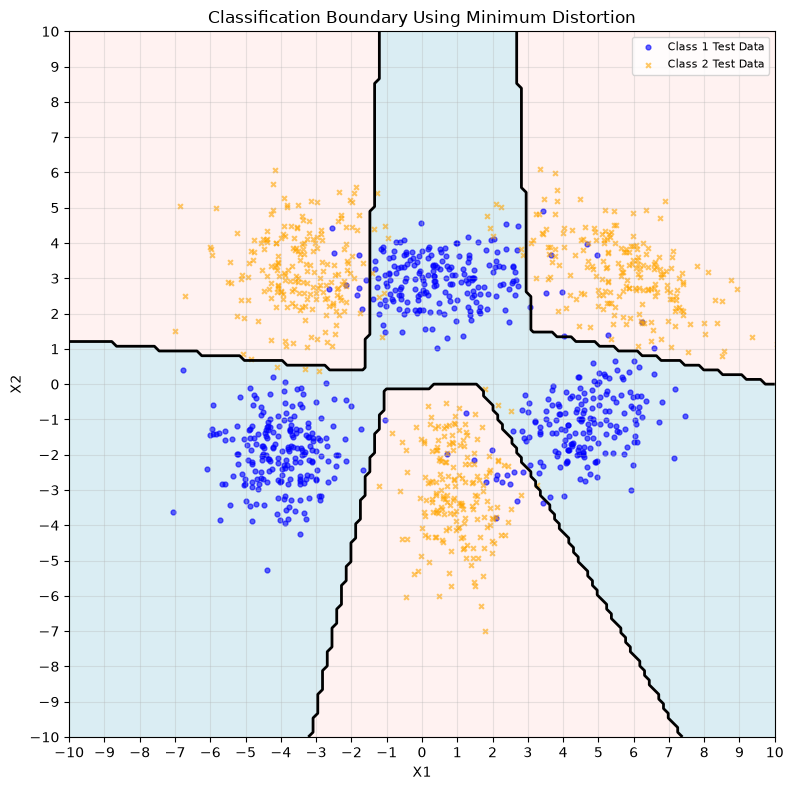

In [12]:
xx, yy = np.meshgrid(
    np.linspace(-10, 10, 150),
    np.linspace(-10, 10, 150)
)

grid = np.column_stack((xx.ravel(), yy.ravel()))

grid_predictions = np.array([
    predict_class(point, centers1, centers2)
    for point in grid
]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(10, 8))

ax.contourf(
    xx, yy, grid_predictions,
    levels=[-0.5, 0.5, 1.5],
    colors=["lightblue", "mistyrose"],
    alpha=0.45
)

ax.contour(
    xx, yy, grid_predictions,
    levels=[0.5],
    colors="black",
    linewidths=2
)

ax.scatter(
    class1_test[:, 0], class1_test[:, 1],
    s=12, alpha=0.6,
    color="blue", marker="o",
    label="Class 1 Test Data"
)

ax.scatter(
    class2_test[:, 0], class2_test[:, 1],
    s=12, alpha=0.6,
    color="orange", marker="x",
    label="Class 2 Test Data"
)

ax.set_title("Classification Boundary Using Minimum Distortion")
set_axes(ax)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()